# O verão no caixa do litoral

Quanto o Pix recebido por empresas sobe nas cidades de frente para o mar entre dezembro e fevereiro, comparado com o resto do país.

Este notebook usa as mesmas funções do pacote `litoral` que geram o site. Cada seção tem a conta, a tabela e o gráfico correspondentes.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from litoral import config, metricas, pipeline, transformacao

FIG = RAIZ / "docs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
MAR, INTERIOR, CORAL = "#0b7a85", "#c4863f", "#d9573b"
MESES = [config.NOMES_MES[m - 1] for m in metricas.ORDEM_CICLO]
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## Dados e cobertura

In [2]:
e = pipeline.carregar()
cadastro = set(e.municipios["municipio"])
pix = e.pix[e.pix["municipio"].isin(cadastro)]
costeiros = e.costeiros & cadastro
painel, cobertura = transformacao.montar_painel(pix, e.municipios, costeiros, e.ipca)
col = "recebido_pj_real"
pd.Series(cobertura)

meses                        67
inicio                  2021-04
fim                     2026-10
municipios                 5567
municipios_litoral          279
excluidos                     4
excluidos_litoral             0
ipca_repetido         [2026-10]
dtype: object

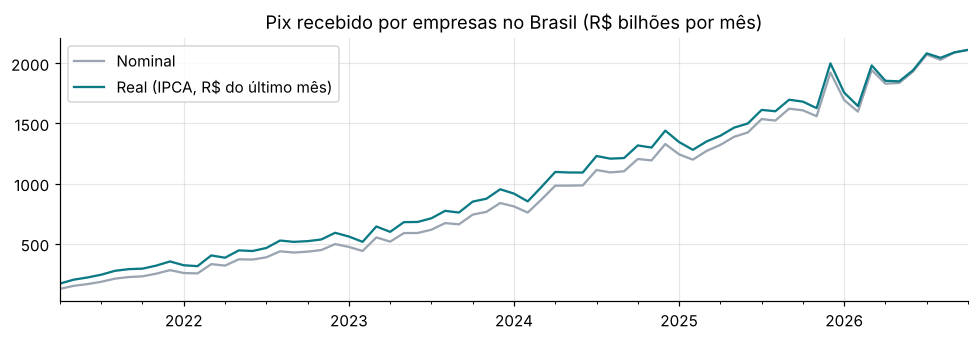

In [3]:
tot = painel.groupby("mes")[["recebido_pj", "recebido_pj_real"]].sum() / 1e9
ax = tot.plot(figsize=(9, 3.2), color=["#9aa5b1", MAR])
ax.set_title("Pix recebido por empresas no Brasil (R$ bilhões por mês)")
ax.set_xlabel(""); ax.legend(["Nominal", "Real (IPCA, R$ do último mês)"])
plt.tight_layout(); plt.savefig(FIG / "01_total.png"); plt.show()

O total cresce muito no período, porque o Pix ainda estava sendo adotado. Por isso nenhuma comparação aqui olha o nível: tudo é medido contra a própria cidade e contra o mesmo mês no resto do país.

## Perfil do ano: litoral contra interior

Índice de cada cidade contra a média de abril a outubro do mesmo ciclo, média geométrica dentro do grupo (cada cidade conta igual) e média entre ciclos.

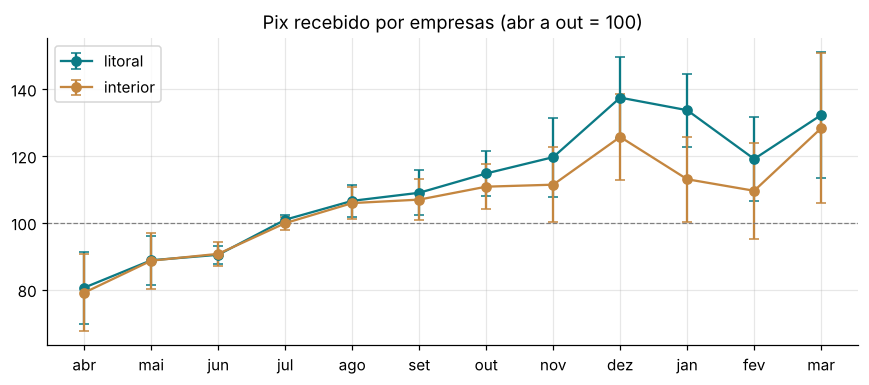

,abr,mai,jun,jul,ago,set,out,nov,dez,jan,fev,mar
interior,79.1000,88.6000,90.7000,99.9000,105.9000,106.9000,110.8000,111.4000,125.7000,113.0000,109.6000,128.3000
litoral,80.6000,88.8000,90.4000,100.9000,106.5000,109.0000,114.7000,119.6000,137.4000,133.7000,119.1000,132.2000


In [4]:
perfil = metricas.perfil_sazonal(painel, col)
tab = perfil.pivot(index="m", columns="litoral", values="media").reindex(metricas.ORDEM_CICLO)
tab.index = MESES; tab.columns = ["interior", "litoral"]
fig, ax = plt.subplots(figsize=(8, 3.6))
for nome, cor in [("litoral", MAR), ("interior", INTERIOR)]:
    sub = perfil[perfil["litoral"] == (nome == "litoral")].set_index("m").reindex(metricas.ORDEM_CICLO)
    ax.errorbar(MESES, sub["media"] * 100, yerr=1.96 * sub["ep"] * 100, color=cor, marker="o", capsize=3, label=nome)
ax.axhline(100, color="gray", ls="--", lw=0.8); ax.legend(); ax.set_title("Pix recebido por empresas (abr a out = 100)")
plt.tight_layout(); plt.savefig(FIG / "02_perfil.png"); plt.show()
(tab * 100).round(1).T

## Modelo de efeitos fixos

$$\log y_{it} = a_i + g_t + \sum_m b_m \cdot 1[\text{mês}(t)=m] \cdot \text{litoral}_i + e_{it}$$

$a_i$ absorve o tamanho de cada cidade, $g_t$ tudo que é comum ao país no mês $t$. Os $b_m$ estão contra a média de abril a outubro; erros padrão agrupados por município.

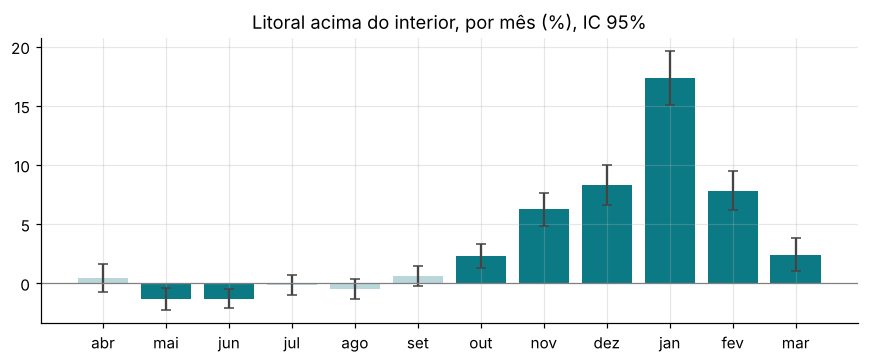

Média dez a fev: +11.1% (IC 95%: +9.4% a +12.8%); 372,989 obs., 5,567 municípios


,coef,ep,p_valor,pct,pct_inf,pct_sup
abr,0.0043,0.0061,0.4794,0.0043,-0.0076,0.0164
mai,-0.0133,0.0049,0.0063,-0.0132,-0.0226,-0.0038
jun,-0.0133,0.0042,0.0015,-0.0132,-0.0213,-0.0051
jul,-0.0015,0.0045,0.7297,-0.0015,-0.0103,0.0073
ago,-0.0053,0.0043,0.2161,-0.0053,-0.0136,0.0031
set,0.0062,0.0042,0.1423,0.0062,-0.0021,0.0145
out,0.0230,0.0050,0.0000,0.0232,0.0131,0.0334
nov,0.0605,0.0067,0.0000,0.0624,0.0485,0.0765
dez,0.0798,0.0080,0.0000,0.0831,0.0663,0.1002
jan,0.1599,0.0099,0.0000,0.1734,0.1508,0.1964


In [5]:
ef = metricas.modelo_efeitos_fixos(painel, col)
efeitos = ef.efeitos.reindex(metricas.ORDEM_CICLO).astype(float)
efeitos.index = MESES
fig, ax = plt.subplots(figsize=(8, 3.4))
sig = (efeitos["pct_inf"] > 0) | (efeitos["pct_sup"] < 0)
ax.bar(MESES, efeitos["pct"] * 100, color=[MAR if s else "#b9d7da" for s in sig])
ax.errorbar(MESES, efeitos["pct"] * 100, yerr=[(efeitos["pct"] - efeitos["pct_inf"]) * 100, (efeitos["pct_sup"] - efeitos["pct"]) * 100],
            fmt="none", ecolor="#444", capsize=3)
ax.axhline(0, color="gray", lw=0.8); ax.set_title("Litoral acima do interior, por mês (%), IC 95%")
plt.tight_layout(); plt.savefig(FIG / "03_efeitos.png"); plt.show()
print(f"Média dez a fev: {ef.temporada['pct']:+.1%} (IC 95%: {ef.temporada['pct_inf']:+.1%} a {ef.temporada['pct_sup']:+.1%}); "
      f"{ef.n_obs:,} obs., {ef.n_municipios:,} municípios")
efeitos[["coef", "ep", "p_valor", "pct", "pct_inf", "pct_sup"]]

## Por temporada

Diferenças em diferenças com litoral x ano: cada temporada contra abril a outubro do mesmo ano.

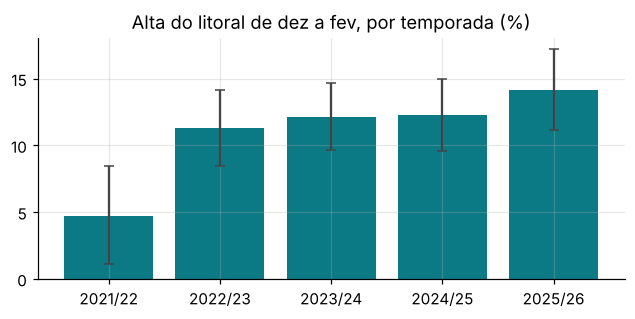

,coef,ep,p_valor,pct,pct_inf,pct_sup
2021/22,0.0460,0.0179,0.0102,0.0471,0.0110,0.0845
2022/23,0.1067,0.0129,0.0000,0.1127,0.0848,0.1412
2023/24,0.1142,0.0114,0.0000,0.1210,0.0963,0.1463
2024/25,0.1156,0.0122,0.0000,0.1225,0.0960,0.1498
2025/26,0.1321,0.0135,0.0000,0.1412,0.1114,0.1718


In [6]:
pt = metricas.efeito_por_temporada(painel, col)
pt.index = [transformacao.rotulo_temporada(a) for a in pt.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(pt.index, pt["pct"] * 100, color=MAR)
ax.errorbar(pt.index, pt["pct"] * 100, yerr=[(pt["pct"] - pt["pct_inf"]) * 100, (pt["pct_sup"] - pt["pct"]) * 100], fmt="none", ecolor="#444", capsize=3)
ax.set_title("Alta do litoral de dez a fev, por temporada (%)")
plt.tight_layout(); plt.savefig(FIG / "04_temporadas.png"); plt.show()
pt

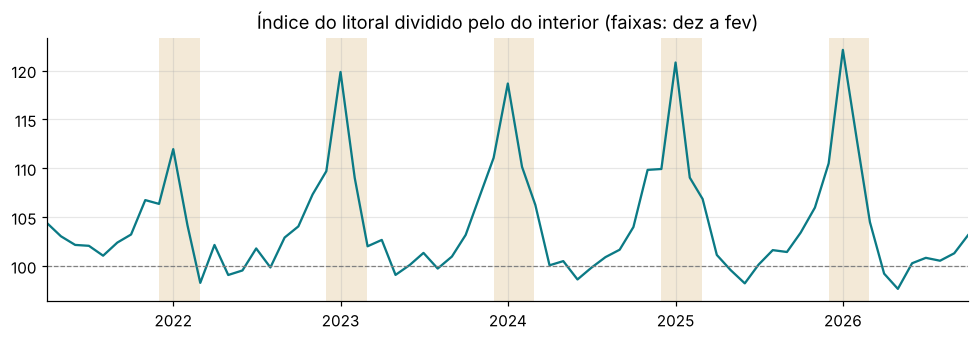

In [7]:
serie = metricas.indice_por_ciclo(painel, col)
razao = serie[True] / serie[False] * 100
fig, ax = plt.subplots(figsize=(9, 3.2))
x = razao.index.to_timestamp()
ax.plot(x, razao.values, color=MAR)
for a in sorted({m.year for m in razao.index}):
    ax.axvspan(pd.Timestamp(f"{a}-12-01"), pd.Timestamp(f"{a + 1}-02-28"), color="#e8d5b0", alpha=0.5, lw=0)
ax.axhline(100, color="gray", ls="--", lw=0.8); ax.set_xlim(x.min(), x.max())
ax.set_title("Índice do litoral dividido pelo do interior (faixas: dez a fev)")
plt.tight_layout(); plt.savefig(FIG / "05_serie.png"); plt.show()

## Robustez

In [8]:
empresas = painel[painel["periodo"] == "base"].groupby("municipio")["empresas"].median()
grandes = set(empresas[empresas >= pipeline.MIN_EMPRESAS_RANKING].index)
variacoes = {
    "Principal": (painel, col, "mes"),
    "Interior do mesmo estado (UF x mês)": (painel, col, "uf_mes"),
    "Sem capitais": (painel[~painel["capital"]], col, "mes"),
    "Cidades com 100+ empresas": (painel[painel["municipio"].isin(grandes)], col, "mes"),
    "Número de transações": (painel, "transacoes_pj", "mes"),
    "Sem 2021/22": (painel[painel["ano_ciclo"] != 2021], col, "mes"),
    "Controle: pago por moradores (PF)": (painel, "pago_pf_real", "mes"),
}
rob = pd.DataFrame({nome: metricas.modelo_efeitos_fixos(d, c_, tempo=t).temporada for nome, (d, c_, t) in variacoes.items()}).T
rob[["pct", "pct_inf", "pct_sup", "p_valor"]]

,pct,pct_inf,pct_sup,p_valor
Principal,0.1107,0.0940,0.1276,0.0000
Interior do mesmo estado (UF x mês),0.0852,0.0685,0.1021,0.0000
Sem capitais,0.1138,0.0966,0.1313,0.0000
Cidades com 100+ empresas,0.1200,0.1026,0.1377,0.0000
Número de transações,0.0903,0.0726,0.1082,0.0000
Sem 2021/22,0.1221,0.1047,0.1398,0.0000
Controle: pago por moradores (PF),0.0412,0.0354,0.0470,0.0000


## Cidades

In [9]:
idx = metricas.adicionar_excesso_tipico(metricas.indice_municipal(painel, col))
cad = e.municipios.set_index("municipio")
cid = idx.groupby("municipio").agg(alta_tipica=("alta", "median"), temporadas=("alta", "size")).join(cad[["nome", "uf", "capital"]])
cid = cid.join(empresas.rename("empresas"))
rank = cid[cid["empresas"] >= pipeline.MIN_EMPRESAS_RANKING].sort_values("alta_tipica", ascending=False)
print("Maiores altas típicas"); display(rank.head(15)[["nome", "uf", "empresas", "alta_tipica"]])
print("Menores altas típicas"); display(rank.tail(10)[["nome", "uf", "empresas", "alta_tipica"]])
print("Capitais"); display(cid[cid["capital"]].sort_values("alta_tipica", ascending=False)[["nome", "uf", "alta_tipica"]])

Maiores altas típicas


,nome,uf,empresas,alta_tipica
municipio,,,,
4202453,Bombinhas,SC,"2,317.0000",0.7979
4301057,Arroio do Sal,RS,766.0000,0.5469
2905404,Cairu,BA,897.5000,0.4762
4310330,Imbé,RS,"1,220.5000",0.4567
3555406,Ubatuba,SP,"5,822.0000",0.4478
4201950,Balneário Arroio do Silva,SC,620.5000,0.4324
4115705,Matinhos,PR,"2,531.5000",0.4296
3204203,Piúma,ES,"1,160.0000",0.4072
2614857,Tamandaré,PE,669.0000,0.4056


Menores altas típicas


,nome,uf,empresas,alta_tipica
municipio,,,,
2706802,Piaçabuçu,AL,174.0000,-0.1314
2404507,Guamaré,RN,324.0000,-0.1373
2101707,Barreirinhas,MA,"1,142.0000",-0.1450
2407203,Macau,RN,544.0000,-0.1456
2110278,Santo Amaro do Maranhão,MA,189.0000,-0.1549
2503209,Cabedelo,PB,"2,299.0000",-0.1658
4313656,Palmares do Sul,RS,475.5000,-0.1897
2111300,São Luís,MA,"38,442.0000",-0.2303
2606200,Goiana,PE,"1,550.0000",-0.2536


Capitais


,nome,uf,alta_tipica
municipio,,,
3205309,Vitória,ES,0.1746
4205407,Florianópolis,SC,0.1032
2800308,Aracaju,SE,0.0616
2611606,Recife,PE,0.0344
2927408,Salvador,BA,0.0291
2704302,Maceió,AL,0.0164
2507507,João Pessoa,PB,0.0124
2304400,Fortaleza,CE,-0.0322
1600303,Macapá,AP,-0.0335


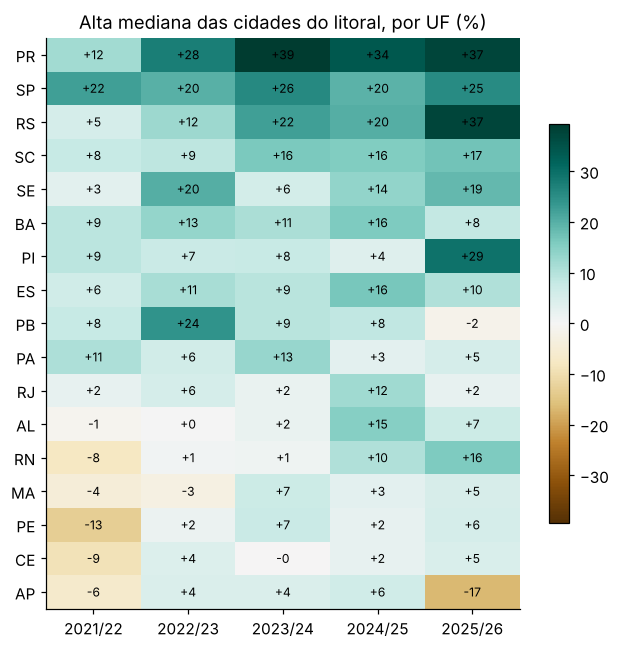

In [10]:
uf = metricas.alta_por_uf(idx)
uf.columns = [transformacao.rotulo_temporada(a) for a in uf.columns]
uf = uf.loc[uf.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6, 6))
lim = np.nanmax(np.abs(uf.values))
im = ax.imshow(uf.values * 100, cmap="BrBG", vmin=-lim * 100, vmax=lim * 100, aspect="auto")
ax.set_xticks(range(len(uf.columns)), uf.columns); ax.set_yticks(range(len(uf.index)), uf.index); ax.grid(False)
for i in range(uf.shape[0]):
    for j in range(uf.shape[1]):
        ax.text(j, i, f"{uf.values[i, j] * 100:+.0f}", ha="center", va="center", fontsize=8)
ax.set_title("Alta mediana das cidades do litoral, por UF (%)"); plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout(); plt.savefig(FIG / "06_ufs.png"); plt.show()

## Valor a mais

Soma do movimento extra (alta típica de cada cidade) fora das capitais.

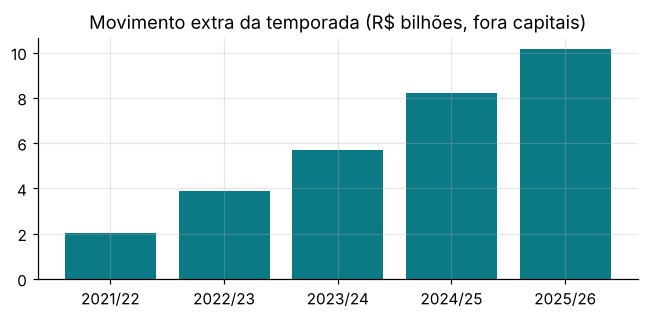

,movimento_bi,excesso_bi,parcela,cidades,cidades_alta_positiva,alta_mediana
2021/22,64.7636,2.0197,0.0312,267,152,0.0433
2022/23,95.7771,3.9017,0.0407,267,187,0.0817
2023/24,146.3719,5.7131,0.0390,267,195,0.0800
2024/25,208.1249,8.2126,0.0395,267,203,0.1038
2025/26,252.3956,10.1382,0.0402,267,202,0.1230


In [11]:
capitais = set(e.municipios.loc[e.municipios["capital"], "municipio"])
exc = metricas.excesso_por_temporada(idx, excluir=capitais)
exc.index = [transformacao.rotulo_temporada(a) for a in exc.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(exc.index, exc["excesso"] / 1e9, color=MAR); ax.set_title("Movimento extra da temporada (R$ bilhões, fora capitais)")
plt.tight_layout(); plt.savefig(FIG / "07_excesso.png"); plt.show()
exc.assign(excesso_bi=exc["excesso"] / 1e9, movimento_bi=exc["movimento_pico"] / 1e9)[["movimento_bi", "excesso_bi", "parcela", "cidades", "cidades_alta_positiva", "alta_mediana"]]

## Leitura

- O litoral fica acima do interior de outubro a março, com pico em janeiro. Novembro já mostra alta, antes das férias.
- O efeito aparece em todas as temporadas e cresceu desde 2021/22, provavelmente porque o Pix passou a ser mais usado por quem viaja.
- O Pix pago por moradores sobe bem menos que o recebido pelas empresas, o que aponta para dinheiro de fora.
- A alta é maior em cidades pequenas e médias de veraneio, principalmente no Sul e em São Paulo, e quase some nas capitais.
- Limitações: Pix não é faturamento, o recebido inclui todos os setores e o município é o do cadastro da empresa. Os resultados são associações.